# Bài tập 2 — Phần A: Harris cổ điển
**Người 2.** Cài đặt Harris cổ điển (`gaussian_blur`, `structure_tensor`, `harris_response`, `nms_2d`, `harris_classic`, `top_n`) và các kiểm chứng A1–A4.

Quy ước: ảnh đưa vào các hàm là **ảnh xám 2D**. Ảnh màu đổi sang xám bằng `cv2.cvtColor` ở bước nạp ảnh.

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

## 1. Cài đặt

### `gaussian_blur`

In [2]:
def gaussian_blur(img, sigma):
    """Làm mờ Gauss. Được phép gọi scipy.ndimage.gaussian_filter."""
    return gaussian_filter(np.asarray(img, dtype=float), sigma=sigma)

### `structure_tensor` — công thức (1), đã nhân σ_D²

In [3]:
def structure_tensor(img, sigma_i, sigma_d):
    """Ma trận mô-men bậc hai theo công thức (1), đã nhân sigma_d**2.
    sigma_d: độ mờ trước khi lấy đạo hàm.
    sigma_i: bán kính cửa sổ lấy trung bình các tích đạo hàm.
    -> (Mxx, Mxy, Myy), mỗi phần tử cùng kích thước ảnh.
    """
    # L = G(sigma_d) * I
    L = gaussian_blur(img, sigma_d)

    # Lx, Ly: sai phân trung tâm ở trong ảnh, sai phân một phía ở viền
    # (np.gradient) -> không còn đạo hàm bị gán cứng bằng 0 ở viền.
    Ly, Lx = np.gradient(L)          # axis 0 = hàng (y), axis 1 = cột (x)

    # G(sigma_i) * [Lx^2, LxLy, Ly^2]
    Mxx = gaussian_blur(Lx * Lx, sigma_i)
    Mxy = gaussian_blur(Lx * Ly, sigma_i)
    Myy = gaussian_blur(Ly * Ly, sigma_i)

    # Chuẩn hóa tỉ lệ Lindeberg: nhân sigma_d^2
    scale = sigma_d ** 2
    return Mxx * scale, Mxy * scale, Myy * scale

### `harris_response` — công thức (2)

In [4]:
def harris_response(img, sigma_i, sigma_d, k=0.04):
    """Đáp ứng R theo công thức (2). -> mảng float cùng kích thước ảnh."""
    Mxx, Mxy, Myy = structure_tensor(img, sigma_i, sigma_d)
    det = Mxx * Myy - Mxy ** 2
    trace = Mxx + Myy
    return det - k * trace ** 2

### `nms_2d`
Vector hóa bằng cách dịch ảnh. Khi đồng hạng chỉ giữ pixel đầu tiên theo thứ tự quét (tất định), nếu không mỗi giao điểm nằm giữa hai pixel sẽ bị trùng nhiều điểm.

In [5]:
def nms_2d(response, window=3):
    """Cực đại địa phương trong cửa sổ window x window. -> mảng bool.

    Tất định khi đồng hạng: nếu nhiều pixel trong cùng một cửa sổ có cùng
    giá trị lớn nhất thì chỉ giữ pixel đầu tiên theo thứ tự quét
    (hàng trước, cột sau). Pixel phải lớn HƠN NGHIÊM NGẶT các lân cận
    đứng trước nó và lớn hơn hoặc bằng các lân cận đứng sau nó.
    Vector hóa bằng cách dịch ảnh, không dùng vòng for theo pixel.
    """
    if window % 2 != 1 or window < 1:
        raise ValueError("window phải là số lẻ.")
    response = np.asarray(response, dtype=float)
    h, w = response.shape
    r = window // 2

    padded = np.pad(response, r, mode='constant', constant_values=-np.inf)
    mask = np.ones((h, w), dtype=bool)

    for dy in range(-r, r + 1):
        for dx in range(-r, r + 1):
            if dy == 0 and dx == 0:
                continue
            nb = padded[r + dy:r + dy + h, r + dx:r + dx + w]
            earlier = (dy < 0) or (dy == 0 and dx < 0)
            mask &= (response > nb) if earlier else (response >= nb)
    return mask

### `harris_classic`

In [6]:
def harris_classic(img, sigma_i=2.0, sigma_d=1.4,
                   k=0.04, thresh_rel=0.01):
    """Harris một tỉ lệ: R -> nms_2d -> ngưỡng tương đối theo max(R).
    -> mảng (N, 3): (row, col, response), sắp xếp giảm dần theo response.
    (row, col) lưu dạng float; ép .astype(int) khi dùng làm chỉ số.
    """
    R = harris_response(img, sigma_i, sigma_d, k)

    max_R = R.max()
    if max_R <= 0:
        return np.empty((0, 3), dtype=float)

    mask = nms_2d(R, window=3) & (R > thresh_rel * max_R)

    rows, cols = np.nonzero(mask)
    corners = np.column_stack((rows, cols, R[rows, cols])).astype(float)

    # Giảm dần theo response; đồng hạng giữ thứ tự quét (sort ổn định)
    order = np.argsort(-corners[:, 2], kind='stable')
    return corners[order]

### `top_n` — đường cơ sở để so với ANMS

In [7]:
def top_n(points, n_keep):
    """Đường cơ sở để so với anms: lấy n_keep điểm mạnh nhất.
    points: mảng (N, 3) (row, col, response). -> mảng (n_keep, 3).
    Nếu N < n_keep thì trả về toàn bộ N điểm.
    """
    points = np.asarray(points, dtype=float)
    order = np.argsort(-points[:, 2], kind='stable')
    return points[order[:n_keep]]

## 2. Nạp ảnh & demo
Ảnh thật: nạp bằng `cv2.imread` rồi đổi xám. Nếu chưa có ảnh trong `anh/`, dùng ảnh tổng hợp bên dưới.

harris_classic: (87, 3) | top_n(30): (30, 3)


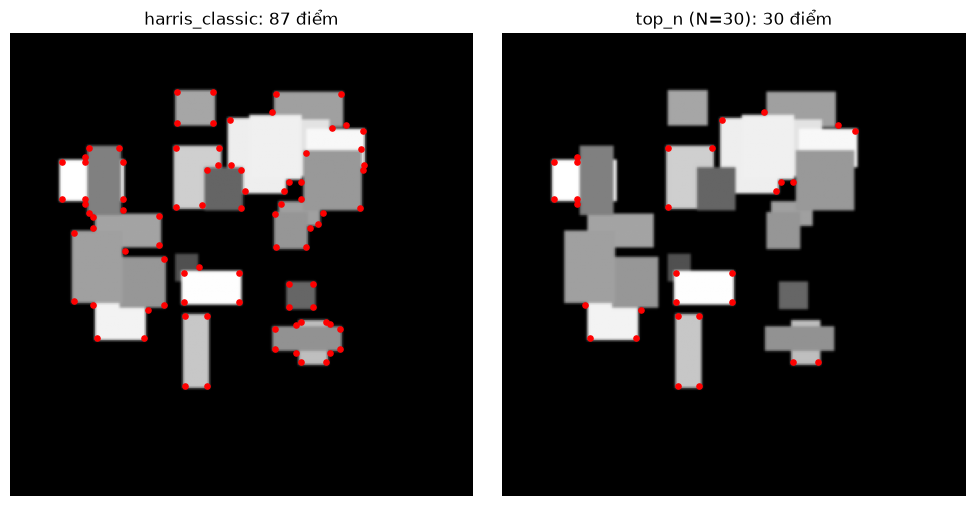

In [8]:
def _make_scene(seed=1, size=300, margin=30, n_rect=25, blur=0.8):
    """Ảnh tổng hợp: nhiều hình chữ nhật trên nền 40, không chạm viền ảnh."""
    rs = np.random.RandomState(seed)
    img = np.full((size, size), 40.0)
    for _ in range(n_rect):
        y, x = rs.randint(margin, size - margin - 50, 2)
        h, w = rs.randint(15, 50, 2)
        img[y:y + h, x:x + w] = rs.randint(100, 255)
    return gaussian_blur(img, blur)


# Ảnh thật (nhóm bỏ comment và đổi đường dẫn):
# img = cv2.imread("anh/xxx.png")
# img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

img = _make_scene()                      # ảnh tổng hợp để demo
pts = harris_classic(img)                # (N, 3): row, col, response (giảm dần)
best = top_n(pts, 30)
print("harris_classic:", pts.shape, "| top_n(30):", best.shape)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
for a, p, t in zip(ax, (pts, best), ("harris_classic", "top_n (N=30)")):
    a.imshow(img, cmap="gray"); a.scatter(p[:, 1], p[:, 0], s=14, c="r")
    a.set_title(f"{t}: {len(p)} điểm"); a.axis("off")
plt.tight_layout(); plt.show()

## 3. Kiểm chứng
Hàm kiểm chứng định nghĩa ở ô đầu, rồi chạy từng ô. `cv2` ở đây chỉ dùng cho biến đổi ảnh và đối chiếu.

In [9]:
def _repeat(pts_a, pts_b, transform, img_shape, eps=3.0):
    """Tỉ lệ điểm của A tìm lại được ở B sau phép biến đổi (chỉ tính điểm
    có ảnh chiếu còn nằm trong B). Cùng ý nghĩa với repeatability() trong tài liệu;
    đặt tên riêng để không đụng hàm chính thức của người phụ trách phần Đo đạc."""
    H, W = img_shape[:2]
    if len(pts_a) == 0 or len(pts_b) == 0:
        return 0.0
    proj = np.array([transform(r, c) for r, c in pts_a[:, :2]])
    ok = (proj[:, 0] >= 0) & (proj[:, 0] <= H - 1) & (proj[:, 1] >= 0) & (proj[:, 1] <= W - 1)
    proj = proj[ok]
    if len(proj) == 0:
        return 0.0
    d = np.linalg.norm(proj[:, None, :] - pts_b[None, :, :2], axis=2).min(axis=1)
    return float((d <= eps).mean())

### A1 — Bàn cờ: đúng giao điểm trong, sai số ≤ 1 px

[A1] điểm=49 (kỳ vọng 49) | sai số lớn nhất=0.71 px | điểm giả=0 | sót=0
     => ĐẠT


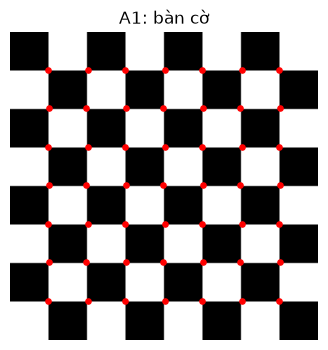

In [9]:
def kiem_chung_A1():
    """A1. Bàn cờ: đúng các giao điểm trong, sai số <= 1 px."""
    board = ((np.indices((160, 160)) // 20).sum(0) % 2 * 255).astype(float)
    pts = harris_classic(board)
    # giao điểm trong nằm giữa hai pixel: toạ độ 20k - 0.5
    truth = np.array([(r - 0.5, c - 0.5) for r in range(20, 160, 20)
                      for c in range(20, 160, 20)])
    d = np.linalg.norm(pts[:, None, :2] - truth[None], axis=2)
    max_err = d.min(axis=0).max()
    n_false = int((d.min(axis=1) > 1.0).sum())
    n_miss = int((d.min(axis=0) > 1.0).sum())
    print(f"[A1] điểm={len(pts)} (kỳ vọng {len(truth)}) | sai số lớn nhất={max_err:.2f} px "
          f"| điểm giả={n_false} | sót={n_miss}")
    ok = len(pts) == len(truth) and n_false == 0 and n_miss == 0 and max_err <= 1.0
    print("     =>", "ĐẠT" if ok else "KHÔNG ĐẠT")
    return ok

assert kiem_chung_A1()
board = ((np.indices((160, 160)) // 20).sum(0) % 2 * 255).astype(float)
p = harris_classic(board)
fig, ax = plt.subplots(figsize=(4, 4)); ax.imshow(board, cmap="gray")
ax.scatter(p[:, 1], p[:, 0], s=14, c="r"); ax.set_title("A1: bàn cờ"); ax.axis("off"); plt.show()

### A2 — Bất biến phép quay (30°)
Nền ảnh quay điền đúng giá trị nền để viền xoay không sinh góc giả.

In [11]:
def kiem_chung_A2(angle=30, eps=3.0):
    """A2. Bất biến phép quay: quay ảnh, chạy lại, đo repeatability."""
    import cv2
    img = _make_scene()
    H, W = img.shape
    M = cv2.getRotationMatrix2D(((W - 1) / 2, (H - 1) / 2), angle, 1.0)
    rot = cv2.warpAffine(img, M, (W, H), flags=cv2.INTER_LINEAR,
                         borderMode=cv2.BORDER_CONSTANT, borderValue=40)  # điền đúng giá trị nền

    def tr(r, c):
        x, y = M @ np.array([c, r, 1.0])
        return y, x

    A, B = harris_classic(img), harris_classic(rot)
    rep = _repeat(A, B, tr, rot.shape, eps)
    print(f"[A2] quay {angle}°: điểm {len(A)} -> {len(B)} | repeatability(eps={eps}) = {rep:.3f}")
    for e in (1.0, 2.0, 5.0):
        print(f"     eps={e}: {_repeat(A, B, tr, rot.shape, e):.3f}")
    return rep

rep = kiem_chung_A2()
assert rep >= 0.8

# Minh họa
im = _make_scene(); H, W = im.shape
M = cv2.getRotationMatrix2D(((W - 1) / 2, (H - 1) / 2), 30, 1.0)
rot = cv2.warpAffine(im, M, (W, H), flags=cv2.INTER_LINEAR,
                     borderMode=cv2.BORDER_CONSTANT, borderValue=40)
fig, ax = plt.subplots(1, 2, figsize=(9, 4.5))
for a, g, t in zip(ax, (im, rot), ("Gốc", "Quay 30°")):
    p = harris_classic(g); a.imshow(g, cmap="gray"); a.scatter(p[:, 1], p[:, 0], s=14, c="r")
    a.set_title(f"{t}: {len(p)} điểm"); a.axis("off")
plt.show()

NameError: name '_repeat' is not defined

### A3 — Tỉ lệ: phóng 3×
Harris cổ điển **không** bất biến tỉ lệ. Góc sắc nét vẫn còn tìm lại được khá nhiều; khi góc *mềm* (kích thước đặc trưng lớn hơn σ) thì sau phóng 3× nó thành cạnh thẳng và bị mất. Khi có `harris_laplace` và `scale_pyramid` trong notebook, ô này tự báo thêm để so sánh.

In [10]:
def kiem_chung_A3(s=3):
    """A3. Tỉ lệ: phóng s lần. Harris cổ điển KHÔNG bất biến tỉ lệ -> kỳ vọng
    repeatability tụt khi góc 'mềm' (kích thước đặc trưng lớn hơn sigma).
    Nếu đã có harris_laplace trong file này thì báo thêm để so sánh."""
    import cv2
    tr = lambda r, c: ((r + 0.5) * s - 0.5, (c + 0.5) * s - 0.5)   # theo tâm pixel
    print(f"[A3] phóng {s}x, harris_classic (sigma cố định):")
    print("     blur | #gốc | #sau | repeatability")
    out = {}
    for blur in (0.8, 2.0, 3.0, 4.0):
        im = _make_scene(blur=blur)
        big = cv2.resize(im, None, fx=s, fy=s, interpolation=cv2.INTER_LINEAR)
        a, b = harris_classic(im), harris_classic(big)
        out[blur] = _repeat(a, b, tr, big.shape, 3.0)
        print(f"     {blur:>4} | {len(a):>4} | {len(b):>4} | {out[blur]:.3f}")
    g = globals()
    if 'harris_laplace' in g and 'scale_pyramid' in g:      # nối tự động khi có A1-Laplace
        im = _make_scene(blur=3.0)
        big = cv2.resize(im, None, fx=s, fy=s, interpolation=cv2.INTER_LINEAR)
        sig = g['scale_pyramid'](1.2, 1.2, 10)
        rl = _repeat(g['harris_laplace'](im, sig), g['harris_laplace'](big, sig), tr, big.shape, 3.0)
        print(f"     harris_laplace (blur=3.0): {rl:.3f}  vs harris_classic: {out[3.0]:.3f}")
    else:
        print("     (chưa có harris_laplace -> chỉ báo harris_classic)")
    return out

res = kiem_chung_A3()
plt.figure(figsize=(4.5, 3)); plt.plot(list(res.keys()), list(res.values()), "o-")
plt.xlabel("độ mờ của góc (sigma)"); plt.ylabel("repeatability (3x)")
plt.ylim(0, 1.05); plt.grid(alpha=.3); plt.show()

[A3] phóng 3x, harris_classic (sigma cố định):
     blur | #gốc | #sau | repeatability


NameError: name '_repeat' is not defined

### A4 — Đối chiếu `cv2.cornerHarris`
Áp NMS 3×3 và ngưỡng 0.01·max cho OpenCV để so công bằng (`cornerHarris` chỉ trả bản đồ đáp ứng).

[A4] điểm của ta=87 | OpenCV=93
     trong <= 1 px của một điểm OpenCV: 98.9%
     trong <= 2 px của một điểm OpenCV: 98.9%
     trong <= 3 px của một điểm OpenCV: 98.9%
     => ĐẠT


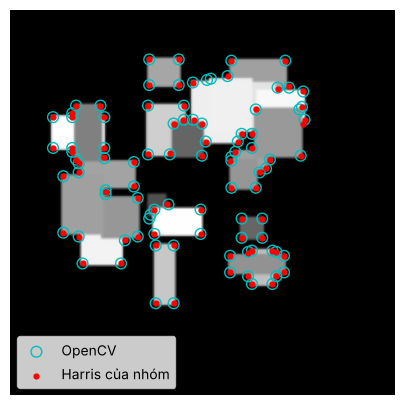

In [13]:
def kiem_chung_A4(min_ratio=0.8):
    """A4. Đối chiếu cv2.cornerHarris: phần lớn điểm của ta nằm trong 2-3 px
    của một điểm OpenCV. Áp NMS 3x3 + ngưỡng 0.01*max cho OpenCV để so công bằng."""
    import cv2
    img = _make_scene()
    mine = harris_classic(img)[:, :2]
    R = cv2.cornerHarris(img.astype(np.float32), blockSize=5, ksize=3, k=0.04)
    loc = (R == cv2.dilate(R, np.ones((3, 3), np.uint8))) & (R > 0.01 * R.max())
    ocv = np.column_stack(np.nonzero(loc))
    d = np.linalg.norm(mine[:, None, :] - ocv[None, :, :], axis=2).min(axis=1)
    print(f"[A4] điểm của ta={len(mine)} | OpenCV={len(ocv)}")
    for r in (1, 2, 3):
        print(f"     trong <= {r} px của một điểm OpenCV: {100 * (d <= r).mean():.1f}%")
    ok = (d <= 3).mean() >= min_ratio
    print("     =>", "ĐẠT" if ok else "KHÔNG ĐẠT")
    return ok

assert kiem_chung_A4()
im = _make_scene(); mine = harris_classic(im)[:, :2]
R = cv2.cornerHarris(im.astype(np.float32), blockSize=5, ksize=3, k=0.04)
loc = (R == cv2.dilate(R, np.ones((3, 3), np.uint8))) & (R > 0.01 * R.max())
ocv = np.column_stack(np.nonzero(loc))
fig, ax = plt.subplots(figsize=(5, 5)); ax.imshow(im, cmap="gray")
ax.scatter(ocv[:, 1], ocv[:, 0], s=60, facecolors="none", edgecolors="c", label="OpenCV")
ax.scatter(mine[:, 1], mine[:, 0], s=12, c="r", label="Harris của nhóm")
ax.legend(); ax.axis("off"); plt.show()

### `top_n`

In [14]:
def kiem_chung_top_n():
    """Kiểm tra top_n: đúng kích thước, giảm dần, N < n_keep trả đủ N."""
    pts = harris_classic(_make_scene())
    t = top_n(pts, 20)
    ok = (t.shape == (20, 3) and bool(np.all(np.diff(t[:, 2]) <= 0))
          and top_n(pts[:3], 20).shape == (3, 3))
    print("[top_n] =>", "ĐẠT" if ok else "KHÔNG ĐẠT")
    return ok

assert kiem_chung_top_n()

[top_n] => ĐẠT


## 4. Tổng kết

In [15]:
def chay_kiem_chung():
    """Chạy toàn bộ kiểm chứng Phần A."""
    kq = {
        "A1": kiem_chung_A1(),
        "A2": kiem_chung_A2() >= 0.8,
    }
    kiem_chung_A3()
    kq["A4"] = kiem_chung_A4()
    kq["top_n"] = kiem_chung_top_n()
    print("\nTổng kết:", {k: ("ĐẠT" if v else "KHÔNG ĐẠT") for k, v in kq.items()})
    return kq

kq = chay_kiem_chung()
assert all(kq.values())

[A1] điểm=49 (kỳ vọng 49) | sai số lớn nhất=0.71 px | điểm giả=0 | sót=0
     => ĐẠT


[A2] quay 30°: điểm 87 -> 88 | repeatability(eps=3.0) = 1.000
     eps=1.0: 0.989
     eps=2.0: 1.000
     eps=5.0: 1.000
[A3] phóng 3x, harris_classic (sigma cố định):
     blur | #gốc | #sau | repeatability


      0.8 |   87 |   99 | 0.805


      2.0 |   80 |   94 | 0.938


      3.0 |   82 |   77 | 0.146


      4.0 |   79 |   44 | 0.165
     (chưa có harris_laplace -> chỉ báo harris_classic)


[A4] điểm của ta=87 | OpenCV=93
     trong <= 1 px của một điểm OpenCV: 98.9%
     trong <= 2 px của một điểm OpenCV: 98.9%
     trong <= 3 px của một điểm OpenCV: 98.9%
     => ĐẠT
[top_n] => ĐẠT

Tổng kết: {'A1': 'ĐẠT', 'A2': 'ĐẠT', 'A4': 'ĐẠT', 'top_n': 'ĐẠT'}
